# One-zone collapse: the test of Menon et al. (2026)

A parcel of gas collapsing at the free-fall rate from $n_{\rm H} = 0.1\,{\rm cm^{-3}}$ and $T = 300$ K, the one-zone test of
Omukai (2000) as Menon et al. (2026, Sec. 3.2 and Fig. 2) set it up, at the seven metallicities of their Fig. 2
($Z = 0$ and $10^{-5}$ to $1\,Z_\odot$), with no FUV field and no cosmic rays (their solid curves). Two models follow
it with `jaco.onezone`:

- `starforge_noneq`: the STARFORGE thermochemistry, with the H ionization evolved in time;
- `popsicle`: the thermochemistry of Menon's KROME collapse test (`jaco.models.popsicle`, whose docstring lists what
  it still lacks).

The `starforge` models read GIZMO's metal-line cooling tables; generate them once with
`python -m jaco.models.starforge.convert_spcool_tables`. Building each model's rate equations (the symbolic reduction
and their compilation) takes a few minutes; the fourteen tracks then take about a minute.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format='retina'
import numpy as np
from matplotlib import pyplot as plt

## The parcels

`starforge_noneq` runs in `OneZone(model, host="menon")`, which closes the parameters a host code would supply as
Menon's parcel has them: a static parcel a Jeans length $\lambda_J = \sqrt{\pi c_s^2 / (G\rho)}$ across, $c_s^2 = P/\rho$,
collapsing at $d\rho/dt = \rho/t_{\rm ff}$, $t_{\rm ff} = \sqrt{3\pi/(32 G\rho)}$, both at the gas density $\rho$. Its
columns are those of Menon's KROME driver: half a Jeans length for the shielding and the lines (the CO lines with a
thermal width), a full one for the dust's optical depth. There is no turbulence. With no radiation field (`ISRF = 0`)
only the CMB heats the dust, and the only ionization of the gas by cosmic rays left is GIZMO's radionuclide floor
($\sim 10^{-19}\,{\rm s^{-1}}$ at $Z_\odot$, none at $Z = 0$).

`popsicle` runs in its own closures, `popsicle.closures.PopsicleClosures` with `host="plain"`: the same free fall and
the KROME driver's columns. Its FUV field `chi_0` and cosmic-ray rate `zeta_CR` are set to 0.

In [2]:
from jaco.onezone import OneZone
from jaco.models import popsicle, starforge_noneq
from jaco.models.popsicle.closures import PopsicleClosures

no_radiation = {"ISRF": 0.0, "G_0": 0.0, "G_LW": 0.0, "z": 0.0}
noneq = OneZone(starforge_noneq.make_model(), params=no_radiation, host="menon")
pops = OneZone(popsicle.make_model(), closures=PopsicleClosures.DEFAULT, host="plain")

## Composition and starting state

Both models start from the composition with which Menon's KROME driver made the solid curves (its version before
2026 May, when the initial H$_2$ was raised): He/H $= 0.0775$, $x_{\rm H^+} = x_e = 10^{-4}$ and
$x_{\rm H_2} = 10^{-6}$ per H. Metals and dust scale with $Z$: for `starforge_noneq` from its solar abundances
(`OneZone.metallicity`), for `popsicle` as in the driver, gas-phase C and O at $0.927\times10^{-4}\,Z$ and
$3.568\times10^{-4}\,Z$ per H (`popsicle.closures.parameters(Z)` sets $1.6\times10^{-4}\,Z$ and
$3.2\times10^{-4}\,Z$, and the gas-phase abundances scale with the totals).

In [3]:
Z_SUN = 0.0142  # solar metal mass fraction
HE_PER_H = 0.0775
START = {"H+": 1e-4, "H_2": 1e-6}
METALLICITIES = (0.0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0)  # in Z_sun


def noneq_parameters(Z):
    # He/H = HE_PER_H through the hydrogen mass fraction X, with metals at Z_SUN Z by mass
    return {**no_radiation, **noneq.metallicity(Z), "X": (1 - Z_SUN * Z) / (1 + 4 * HE_PER_H)}


def popsicle_parameters(Z):
    p = {**popsicle.closures.parameters(Z), "chi_0": 0.0, "zeta_CR": 0.0, "y": HE_PER_H, "X": 1 / (1 + 4 * HE_PER_H)}
    p["x_C,tot"] *= 0.927e-4 / popsicle.closures.C_GAS_SOLAR
    p["x_O,tot"] *= 3.568e-4 / popsicle.closures.O_GAS_SOLAR
    return p


def collapse(zone, n_stop=1e18):
    # the free-fall track from 0.1 cm^-3 and 300 K to n_stop; popsicle's state solve can fail in the runaway it
    # starts above ~2e16 cm^-3 (at Z_sun), and the track then ends at half the density
    try:
        return zone.free_fall(n0=0.1, T0=300.0, n_stop=n_stop, x0=dict(START), n_points=600)
    except Exception as err:
        print(f"failed on the way to n_H = {n_stop:.0e} ({type(err).__name__}); stopping at {n_stop / 2:.0e}")
        return zone.free_fall(n0=0.1, T0=300.0, n_stop=n_stop / 2, x0=dict(START), n_points=600)


tracks = {}
for name, zone, parameters in (("starforge_noneq", noneq, noneq_parameters),
                               ("popsicle", pops, popsicle_parameters)):
    for Z in METALLICITIES:
        zone.params = parameters(Z)
        tracks[name, Z] = collapse(zone)

failed on the way to n_H = 1e+18 (ZeroDivisionError); stopping at 5e+17


## Comparison with Menon et al. (2026), Fig. 2

Their solid curves are in `menon26_curves/` (see its README).

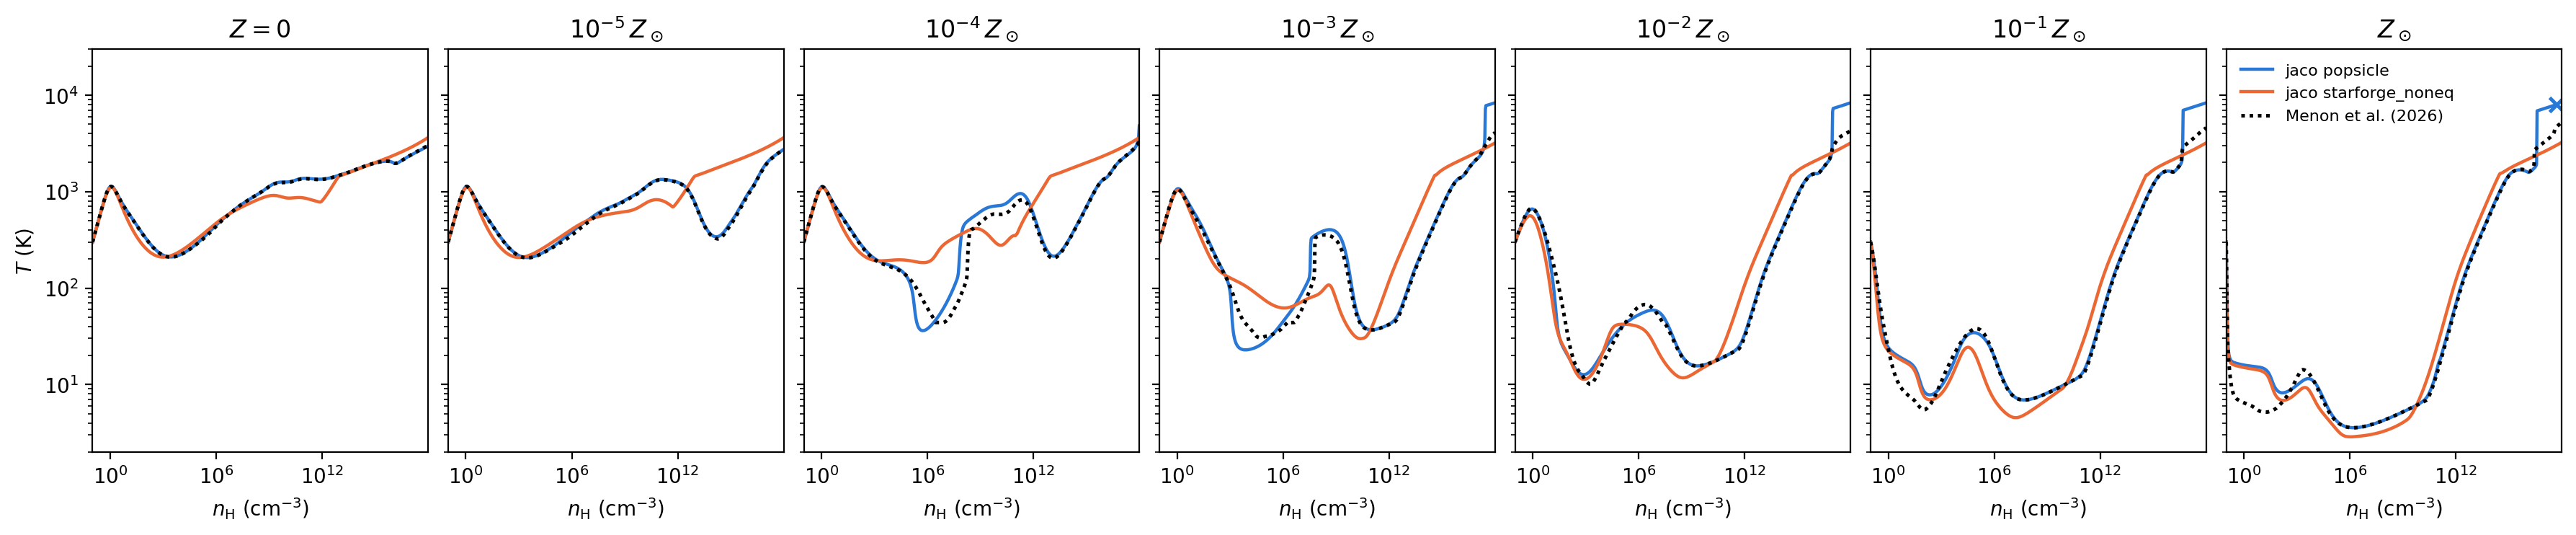

In [4]:
CURVES = {0.0: "Z0", 1e-5: "Z1e-5", 1e-4: "Z1e-4", 1e-3: "Z1e-3", 1e-2: "Z1e-2", 1e-1: "Z1e-1", 1.0: "Zsun"}
TITLES = {0.0: r"$Z = 0$", 1e-5: r"$10^{-5}\,Z_\odot$", 1e-4: r"$10^{-4}\,Z_\odot$", 1e-3: r"$10^{-3}\,Z_\odot$",
          1e-2: r"$10^{-2}\,Z_\odot$", 1e-1: r"$10^{-1}\,Z_\odot$", 1.0: r"$Z_\odot$"}
STYLE = {"popsicle": dict(color="#2a78d6", label="jaco popsicle"),
         "starforge_noneq": dict(color="#eb6834", label="jaco starforge_noneq")}

fig, axes = plt.subplots(1, 7, figsize=(18, 3.9), sharex=True, sharey=True)
for ax, Z in zip(axes, METALLICITIES):
    for name in ("popsicle", "starforge_noneq"):
        n, T = tracks[name, Z]["n_Htot"], tracks[name, Z]["T"]
        ax.loglog(n, T, lw=1.6, **STYLE[name])
        if n[-1] < 0.99e18:  # stopped short
            ax.plot(n[-1], T[-1], "x", color=STYLE[name]["color"], ms=7, mew=1.8)
    lg_n, lg_T = np.loadtxt(f"menon26_curves/Tgas_nH_{CURVES[Z]}_chiFUV0.csv", delimiter=",", skiprows=1).T
    ax.loglog(10 ** lg_n, 10 ** lg_T, color="black", lw=1.8, ls=(0, (1, 1.3)), label="Menon et al. (2026)")
    ax.set_title(TITLES[Z])
    ax.set_xlim(1e-1, 1e18)
    ax.set_ylim(2, 3e4)
    ax.set_xticks([1e0, 1e6, 1e12])
    ax.set_xlabel(r"$n_{\rm H}\ ({\rm cm^{-3}})$")
axes[0].set_ylabel(r"$T$ (K)")
axes[-1].legend(loc="upper left", frameon=False, fontsize=8)
fig.tight_layout()
fig.subplots_adjust(wspace=0.06)

`popsicle`, which follows Menon's KROME network, is within 0.03 dex of their curves (the median over
$n_{\rm H} < 2\times10^{16}\,{\rm cm^{-3}}$) at every metallicity. Where it departs, it lacks parts of their network
(its docstring lists them). Its carbon is starforge's C$^+$/CO partition, which keeps all the carbon in C$^+$ up to
$n_{\rm H} \sim 30\,{\rm cm^{-3}}$: at $Z_\odot$ the gas then cools through [CII] alone and stalls near 15 K, where
Menon's falls to 5-6 K through C and CO (likewise, less so, at $0.1\,Z_\odot$). At $10^{-4}\,Z_\odot$, between $10^6$
and $10^{10}\,{\rm cm^{-3}}$, Menon's Fig. 3 has OH and H$_2$O among the main coolants, and `popsicle` has neither.
Above $\sim 2\times10^{16}\,{\rm cm^{-3}}$, at $Z \geq 10^{-3}\,Z_\odot$, it heats to $\sim 8000$ K, which Menon's gas
does not; at $Z_\odot$ its state solve then fails, and that track stops at $5\times10^{17}\,{\rm cm^{-3}}$.

`starforge_noneq` is a different network and is further off, 0.04-0.25 dex in the median. At $Z = 0$ and
$10^{-5}\,Z_\odot$ it is up to 0.23 dex too cold between $10^9$ and $10^{13}\,{\rm cm^{-3}}$, since its H$_2$ line
cooling has no line-opacity factor. From $10^{-5}$ to $10^{-1}\,Z_\odot$ it is up to 0.8 dex too hot above
$\sim 10^{12}\,{\rm cm^{-3}}$, and at $Z_\odot$ it has `popsicle`'s [CII]-only gap at low density.